### Vorverarbeitung der Daten

,date,KWH,kwh,meters
0,2011-11-23 09:00:00,0.569000,0.284500,2
1,2011-11-23 09:30:00,0.561000,0.280500,2
2,2011-11-23 10:00:00,0.920000,0.153333,6
3,2011-11-23 10:30:00,0.588000,0.098000,6
4,2011-11-23 11:00:00,0.772000,0.110286,7
...,...,...,...,...
40400,2014-02-27 22:00:00,1494.603000,0.299760,4986
40401,2014-02-27 22:30:00,1422.109001,0.285163,4987
40402,2014-02-27 23:00:00,1258.090000,0.252274,4987
40403,2014-02-27 23:30:00,1073.622001,0.215284,4987


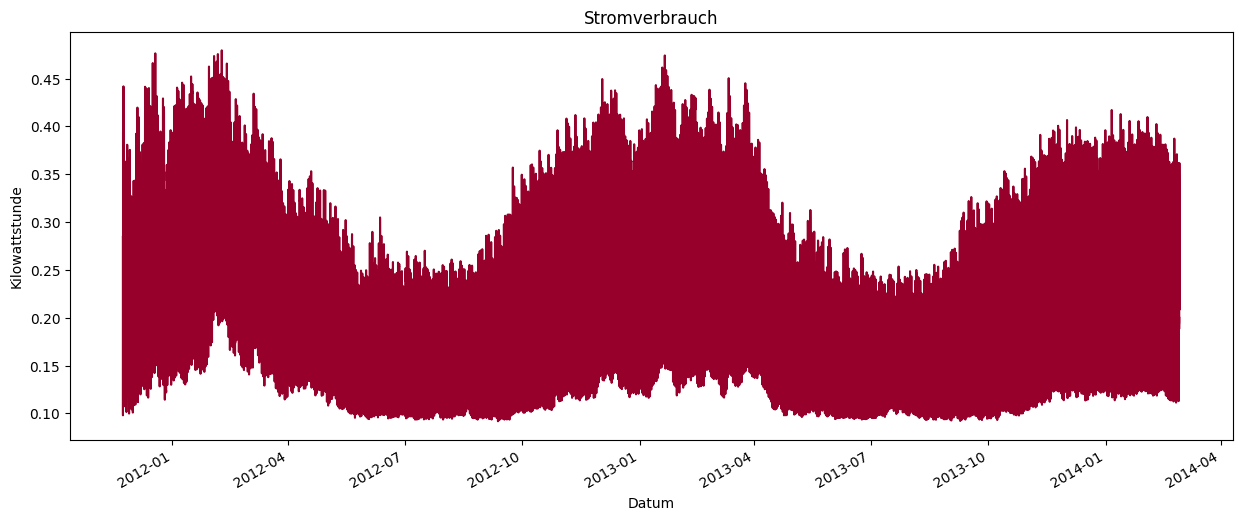

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("data.csv")
df["date"] = pd.to_datetime(df["DateTime"])

# Tarife werden vorerst zusammengelegt
df = df.groupby("date", as_index=False).agg({"KWH": "sum", "meters": "sum"}).reset_index()

# Normalisierung: Stromverbrauch eines Verbrauchers für jeden Zeitpunkt
df["kwh"] = df["KWH"] / df["meters"]

df = df[["date", "KWH", "kwh", "meters"]]
display(df)

# Erste Visualisierung des Datensatzes
series = df.set_index("date")["kwh"].sort_index()
fig, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#96002A")
ax.set(
    title="Stromverbrauch",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
plt.show()

### Datenbereinigung

Im Datensatz sind fehlerhaft Datenpunkte enthalten, bei denen kein Verbraucher geschaltet ist und die Messungen außerhalb dem 30-Minuten-Taktes liegen.

In [7]:
# Prüfung auf Datenpunkte mit keinem Verbrauch
display(df.loc[(df["KWH"] == 0)])

# Falls die Prüfungen nichts zurücklieferen, können die fehlerhaften Datenpunkte entfernt werden
# Prüfung auf korrekte Datenpunkte mit keinem Verbrauch
display(df.loc[(df["KWH"] == 0) & ((df["date"].dt.minute % 30 == 0) & (df["date"].dt.second == 0))])
# Prüfung auf korrekte Datenpunkte außerhalb des 30-Minuten-Taktes
display(df.loc[~(df["KWH"] == 0) & ~((df["date"].dt.minute % 30 == 0) & (df["date"].dt.second == 0))])

# Durch .asfreq() fallen die fehlerhaften Datenpunkte weg
df = df.set_index("date")[["kwh"]].sort_index().asfreq("30min")
display(df["kwh"].isna().sum())

,date,KWH,kwh,meters
18781,2012-12-18 15:13:26,0.0,NaN,0
18782,2012-12-18 15:13:27,0.0,NaN,0
18783,2012-12-18 15:13:28,0.0,NaN,0
18784,2012-12-18 15:13:29,0.0,NaN,0
18785,2012-12-18 15:13:30,0.0,NaN,0
...,...,...,...,...
29001,2013-07-05 12:54:31,0.0,NaN,0
29003,2013-07-05 13:15:05,0.0,NaN,0
32710,2013-09-20 18:24:09,0.0,NaN,0
34566,2013-10-29 09:33:01,0.0,NaN,0


,date,KWH,kwh,meters


,date,KWH,kwh,meters


np.int64(0)

### Untersuchung der Zeitreihe

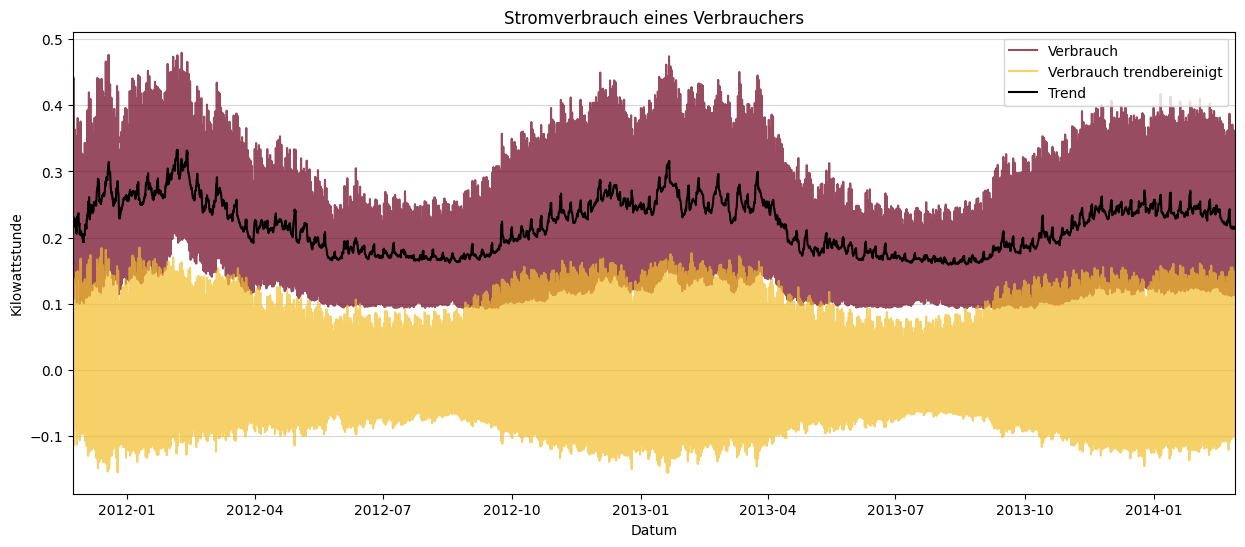

,kwh,kwh_trend,kwh_trendbereinigt
date,,,
2011-11-23 09:00:00,0.284500,NaN,NaN
2011-11-23 09:30:00,0.280500,NaN,NaN
2011-11-23 10:00:00,0.153333,NaN,NaN
2011-11-23 10:30:00,0.098000,NaN,NaN
2011-11-23 11:00:00,0.110286,NaN,NaN
...,...,...,...
2014-02-27 22:00:00,0.299760,NaN,NaN
2014-02-27 22:30:00,0.285163,NaN,NaN
2014-02-27 23:00:00,0.252274,NaN,NaN


In [ ]:
import matplotlib.dates as mdates


def analyse_trend(df: pd.DataFrame) -> pd.DataFrame:
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.margins(x=0)

    x = mdates.date2num(df.index)
    p = np.poly1d(np.polyfit(x, df["kwh"], 1))
    # df["kwh_trend"] = p(x)  # Linearer Trend
    # TODO: Festlegung Fenstergröße / oder einfach linearen Trend nehmen
    df["kwh_trend"] = df["kwh"].rolling(window=48, center=True).mean()  # Mit Glättung

    df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]
    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.7, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.7, label="Verbrauch trendbereinigt")
    ax.plot(df.index, df["kwh_trend"], color="#000000", alpha=1, label="Trend")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.5)
    plt.show()

    return df


df = analyse_trend(df)
df

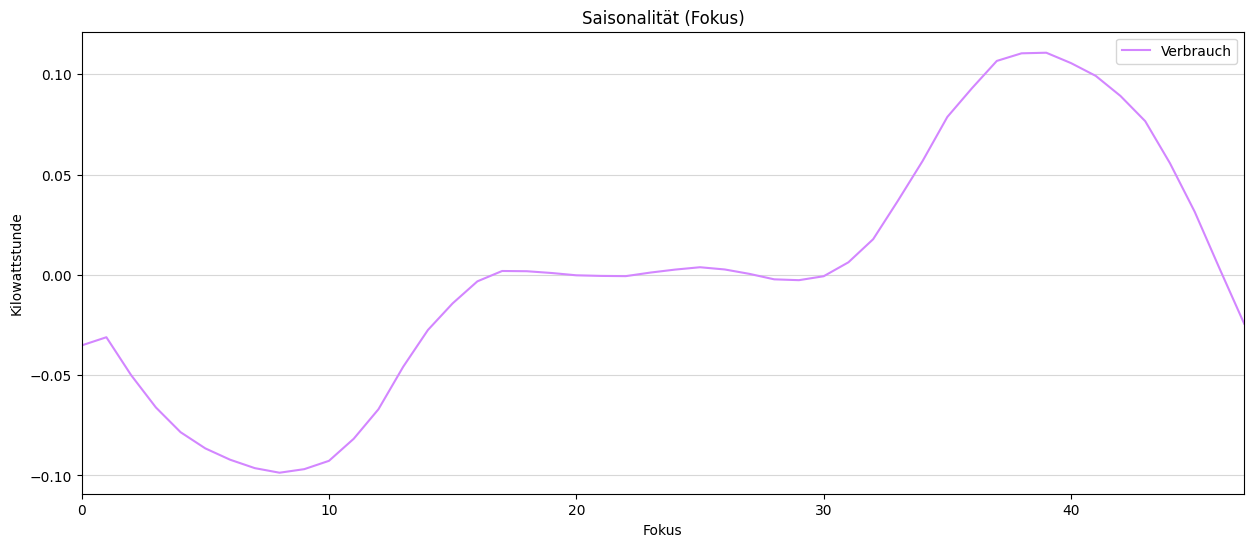

,kwh,kwh_trend,kwh_trendbereinigt,focus,kwh_trendbereinigt_saison
date,,,,,
2011-11-23 09:00:00,0.284500,NaN,NaN,18,0.001833
2011-11-23 09:30:00,0.280500,NaN,NaN,19,0.000950
2011-11-23 10:00:00,0.153333,NaN,NaN,20,-0.000196
2011-11-23 10:30:00,0.098000,NaN,NaN,21,-0.000505
2011-11-23 11:00:00,0.110286,NaN,NaN,22,-0.000614
...,...,...,...,...,...
2014-02-27 22:00:00,0.299760,NaN,NaN,44,0.055706
2014-02-27 22:30:00,0.285163,NaN,NaN,45,0.031505
2014-02-27 23:00:00,0.252274,NaN,NaN,46,0.003322


In [9]:
def analyse_seasonality(df: pd.DataFrame) -> pd.DataFrame:
    # .hour, .dayofweek, .day
    df["focus"] = df.index.hour * 2 + df.index.minute // 30  # 48 Zeitpunkte pro Tag

    seasonal = df.groupby("focus")["kwh_trendbereinigt"].mean()

    fig, ax = plt.subplots(figsize=(15, 6))
    ax.margins(x=0)

    seasonal.plot(ax=ax, color="#D386FF", alpha=1, label="Verbrauch")
    ax.set(
        title="Saisonalität (Fokus)",
        xlabel="Fokus",
        ylabel="Kilowattstunde",
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.5)
    plt.show()

    return df.join(seasonal, on="focus", rsuffix="_saison")


df = analyse_seasonality(df)
df

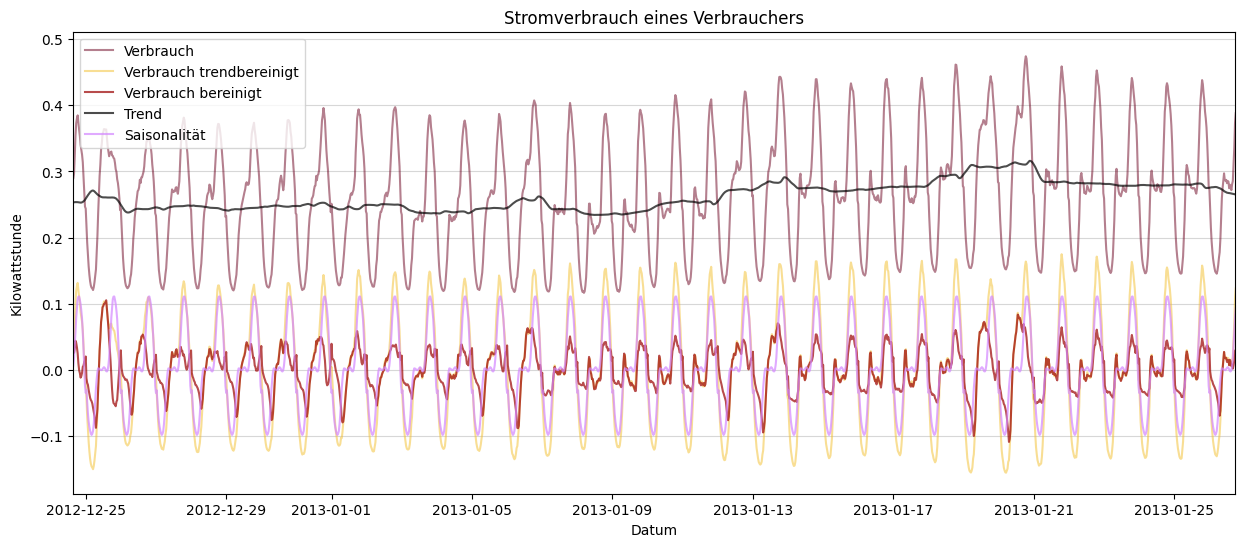

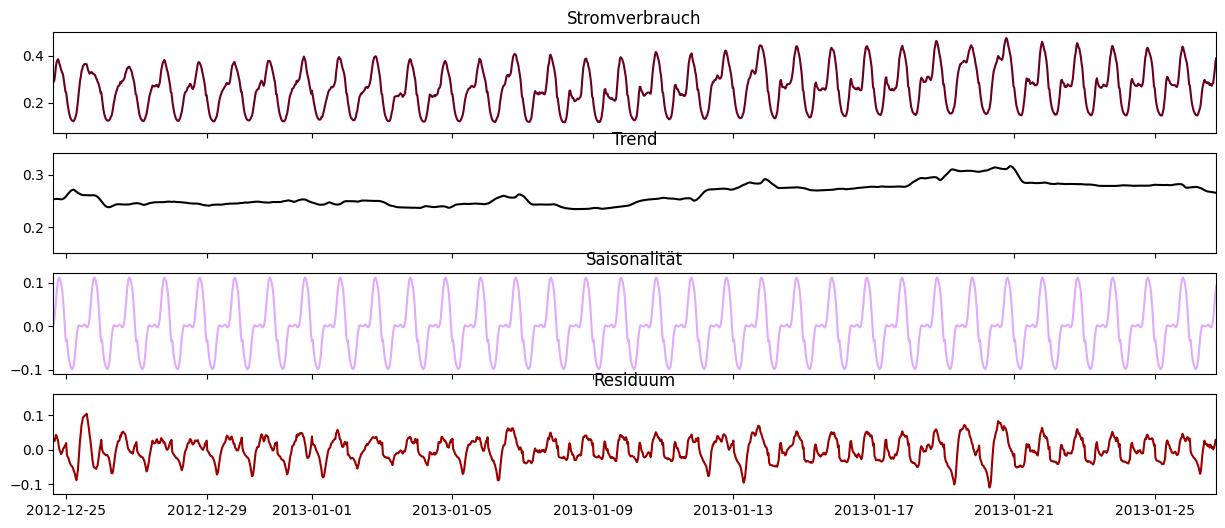

In [ ]:
def analyse_cleaned(df: pd.DataFrame) -> pd.DataFrame:
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.margins(x=0)
    # TODO: Hier sollte gleiches Ergebnis wie mit .shift(48) rauskommen???
    df["kwh_bereinigt"] = df["kwh_trendbereinigt"] - df["kwh_trendbereinigt_saison"]
    # df["kwh_bereinigt"] = df["kwh"] - df["kwh"].shift(48)
    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.5, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.5, label="Verbrauch trendbereinigt")
    ax.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.7, label="Verbrauch bereinigt")
    ax.plot(df.index, df["kwh_trend"], color="#000000FF", alpha=0.7, label="Trend")
    ax.plot(df.index, df["kwh_trendbereinigt_saison"], color="#D386FF", alpha=0.7, label="Saisonalität")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.set_xlim(pd.Series(df.index).quantile(0.48), pd.Series(df.index).quantile(0.52))  # Begrenzung auf Zeitraum
    ax.legend()
    ax.grid(axis="y", alpha=0.5)
    plt.show()

    # Getrennte Plots
    fig, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.48), pd.Series(df.index).quantile(0.52))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(df["kwh_trend"], color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(df["kwh_trendbereinigt_saison"], color="#D386FF", alpha=0.7)
    ax[2].set_title("Saisonalität")

    ax[3].plot(df["kwh_bereinigt"], color="#9B0000")
    ax[3].set_title("Residuum")

    plt.show()
    return df


df = analyse_cleaned(df)

In [11]:
from statsmodels.tsa.seasonal import STL

decomposition = STL(
    df["kwh"],
    period=48,
)
decomposition = decomposition.fit()
# _ = decomposition.plot()

In [ ]:
# from statsmodels.tsa.seasonal import seasonal_decompose

# decomposition = seasonal_decompose(df["kwh"], model="additive", period=48)
# _ = decomposition.plot()

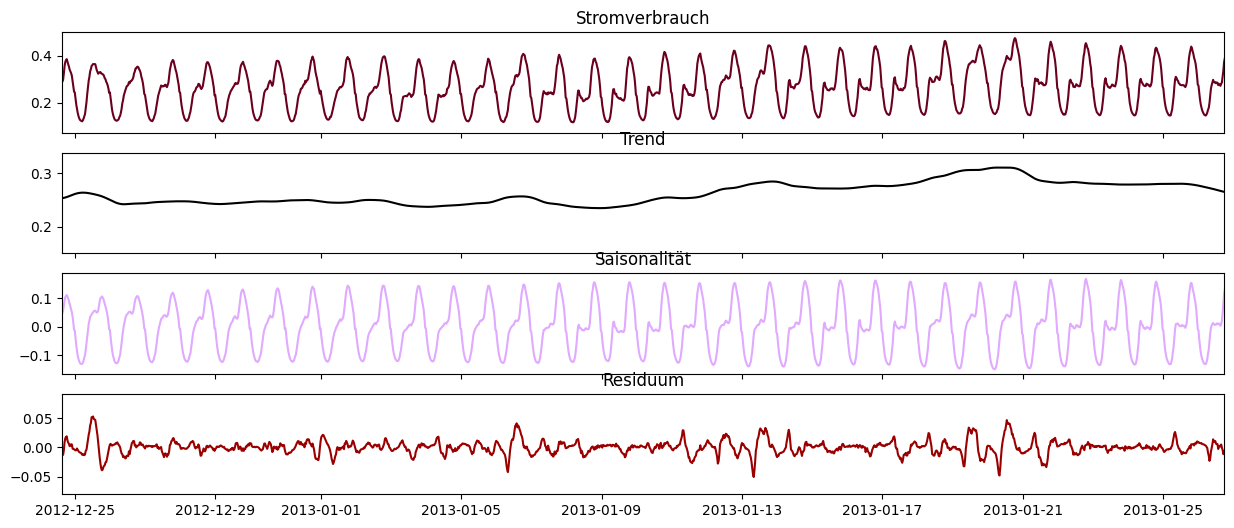

In [12]:
fig, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

for p in ax:
    p.set_xlim(pd.Series(df.index).quantile(0.48), pd.Series(df.index).quantile(0.52))

ax[0].plot(df["kwh"], color="#6B001E")
ax[0].set_title("Stromverbrauch")

ax[1].plot(decomposition.trend, color="#000000FF")
ax[1].set_title("Trend")

ax[2].plot(decomposition.seasonal, color="#D386FF", alpha=0.7)
ax[2].set_title("Saisonalität")

ax[3].plot(decomposition.resid, color="#9B0000")
ax[3].set_title("Residuum")

plt.show()

kwh_bereinigt:


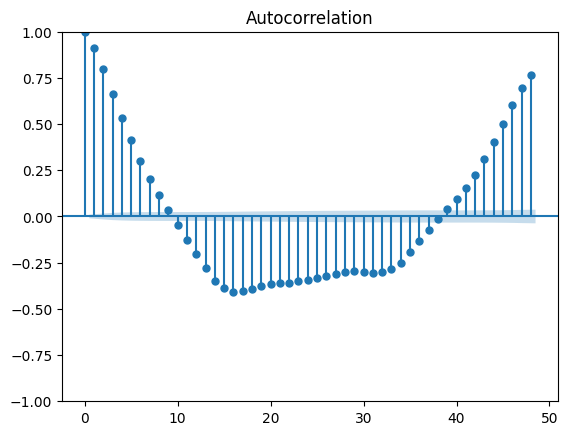

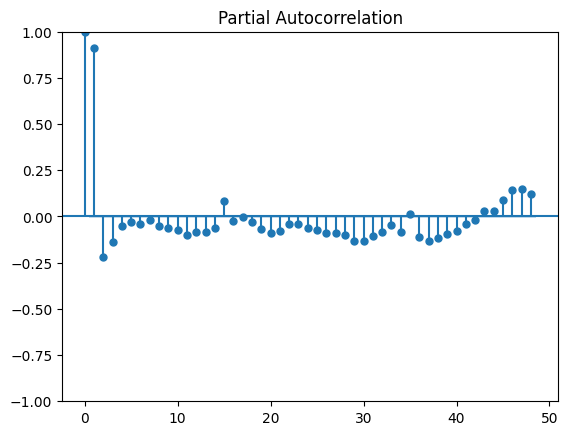

statsmodels STL (Season-Trend decomposition using LOESS):


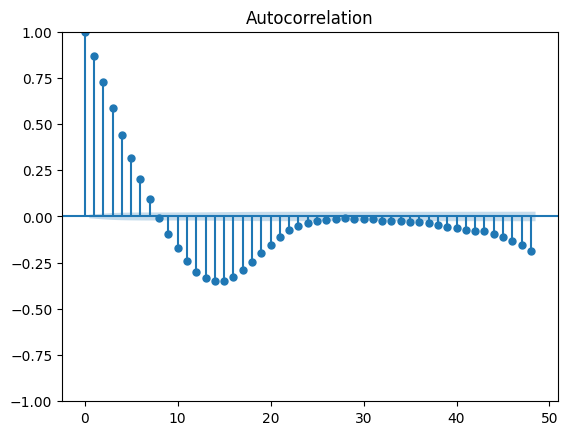

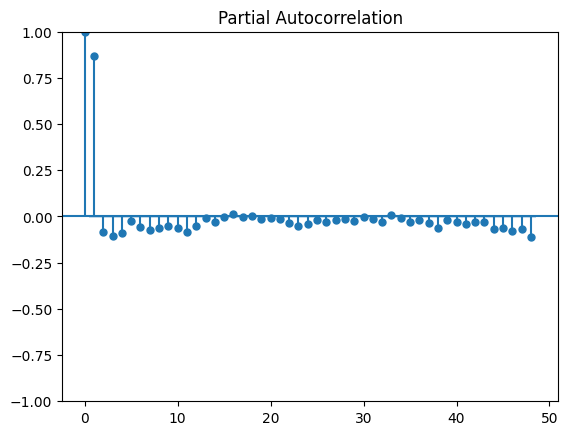

In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

print("kwh_bereinigt:")
_ = plot_acf(df["kwh_bereinigt"].dropna(), lags=48)
_ = plot_pacf(df["kwh_bereinigt"].dropna(), lags=48)
plt.show()
print("statsmodels STL (Season-Trend decomposition using LOESS):")
_ = plot_acf(decomposition.resid.dropna(), lags=48)
_ = plot_pacf(decomposition.resid.dropna(), lags=48)
plt.show()

### Vorhersage

In [ ]:
# Beispiel aus Übung
from sklearn.linear_model import LinearRegression

df_model = df.copy()
df_model["kwh_bereinigt_t-1"] = df_model.kwh_bereinigt.shift(1)
df_model["kwh_bereinigt_t-2"] = df_model.kwh_bereinigt.shift(2)
df_model["kwh_bereinigt_t-3"] = df_model.kwh_bereinigt.shift(3)
df_model = df_model.dropna(
    subset=["kwh_bereinigt", "kwh_bereinigt_t-1", "kwh_bereinigt_t-2", "kwh_bereinigt_t-3"]
).copy()

X = df_model[["kwh_bereinigt_t-1", "kwh_bereinigt_t-2", "kwh_bereinigt_t-3"]]
y = df_model["kwh_bereinigt"]

model = LinearRegression()
model.fit(X, y)

df_model["kwh_vorhersage"] = model.predict(X)

df_prediction = df.merge(df_model["kwh_vorhersage"], left_index=True, right_index=True)

print("Regression Coefficients:", model.coef_)
print("Regression Intercept:", model.intercept_)
df_prediction.tail(40)

Regression Coefficients: [ 1.08124299 -0.06704273 -0.13525533]
Regression Intercept: -2.19595031954251e-06


,kwh,kwh_trend,kwh_trendbereinigt,focus,kwh_trendbereinigt_saison,kwh_bereinigt,kwh_vorhersage
date,,,,,,,
2014-02-26 17:00:00,0.226615,0.212878,0.013737,34,0.056822,-0.043085,-0.039216
2014-02-26 17:30:00,0.259592,0.212834,0.046758,35,0.078781,-0.032024,-0.039154
2014-02-26 18:00:00,0.305174,0.212846,0.092328,36,0.093161,-0.000834,-0.026064
2014-02-26 18:30:00,0.340639,0.212943,0.127696,37,0.106710,0.020986,0.007071
2014-02-26 19:00:00,0.356906,0.212870,0.144036,38,0.110508,0.033528,0.027076
2014-02-26 19:30:00,0.361744,0.212770,0.148973,39,0.110801,0.038173,0.034955
2014-02-26 20:00:00,0.356948,0.212833,0.144114,40,0.105624,0.038491,0.036185
2014-02-26 20:30:00,0.344179,0.212995,0.131184,41,0.099251,0.031933,0.034522
2014-02-26 21:00:00,0.328457,0.213128,0.115329,42,0.089236,0.026093,0.026782


In [17]:
# TODO: ???
from sklearn import metrics
from sklearn.linear_model import LinearRegression

df_model = df.copy()

for lag in range(1, 13):
    df_model[f"kwh_bereinigt_t-{lag}"] = df_model.kwh_bereinigt.shift(lag)

lags = [f"kwh_bereinigt_t-{lag}" for lag in range(1, 13)]

df_model = df_model.dropna()

X = df_model[lags]
y = df_model["kwh_bereinigt"]

model = LinearRegression()
model.fit(X, y)

df_model["kwh_vorhersage"] = model.predict(X)

df_prediction = df.merge(df_model["kwh_vorhersage"], left_index=True, right_index=True)
df_prediction = df_prediction.dropna()

print(
    f"Regression Intercept: {model.intercept_}\n"
    f"Regression Coefficients: {model.coef_}\n"
    f"R²:\t{metrics.r2_score(df_model['kwh_bereinigt'].tail(len(df_prediction)), df_prediction['kwh_vorhersage'])}\n"
    f"RMSE:\t{metrics.root_mean_squared_error(df_model['kwh_bereinigt'].tail(len(df_prediction)), df_prediction['kwh_vorhersage'])}\n"
    f"MAE:\t{metrics.mean_absolute_error(df_model['kwh_bereinigt'].tail(len(df_prediction)), df_prediction['kwh_vorhersage'])}\n"
)
df_prediction.head(30)

Regression Intercept: -1.5215696868707798e-06
Regression Coefficients: [ 1.05064943 -0.07228549 -0.0808247  -0.02070165 -0.00276514 -0.02204005
  0.01413558  0.00152891  0.00456332  0.02619585 -0.01063762 -0.08469456]
R²:	0.8496603903413557
RMSE:	0.009913011892118361
MAE:	0.006221690477865344



,kwh,kwh_trend,kwh_trendbereinigt,focus,kwh_trendbereinigt_saison,kwh_bereinigt,kwh_vorhersage
date,,,,,,,
2011-11-24 03:00:00,0.141769,0.220681,-0.078912,6,-0.092154,0.013242,-0.010064
2011-11-24 03:30:00,0.138462,0.220564,-0.082103,7,-0.096363,0.014260,0.001921
2011-11-24 04:00:00,0.134692,0.221330,-0.086638,8,-0.098650,0.012012,0.006116
2011-11-24 04:30:00,0.122154,0.221733,-0.099579,9,-0.096871,-0.002708,0.010678
2011-11-24 05:00:00,0.107385,0.221261,-0.113876,10,-0.092717,-0.021159,-0.005354
2011-11-24 05:30:00,0.114308,0.221815,-0.107508,11,-0.081714,-0.025794,-0.020076
2011-11-24 06:00:00,0.123538,0.222489,-0.098951,12,-0.066995,-0.031956,-0.024567
2011-11-24 06:30:00,0.138923,0.222628,-0.083705,13,-0.045806,-0.037899,-0.039001
2011-11-24 07:00:00,0.170308,0.224725,-0.054418,14,-0.027467,-0.026951,-0.043098


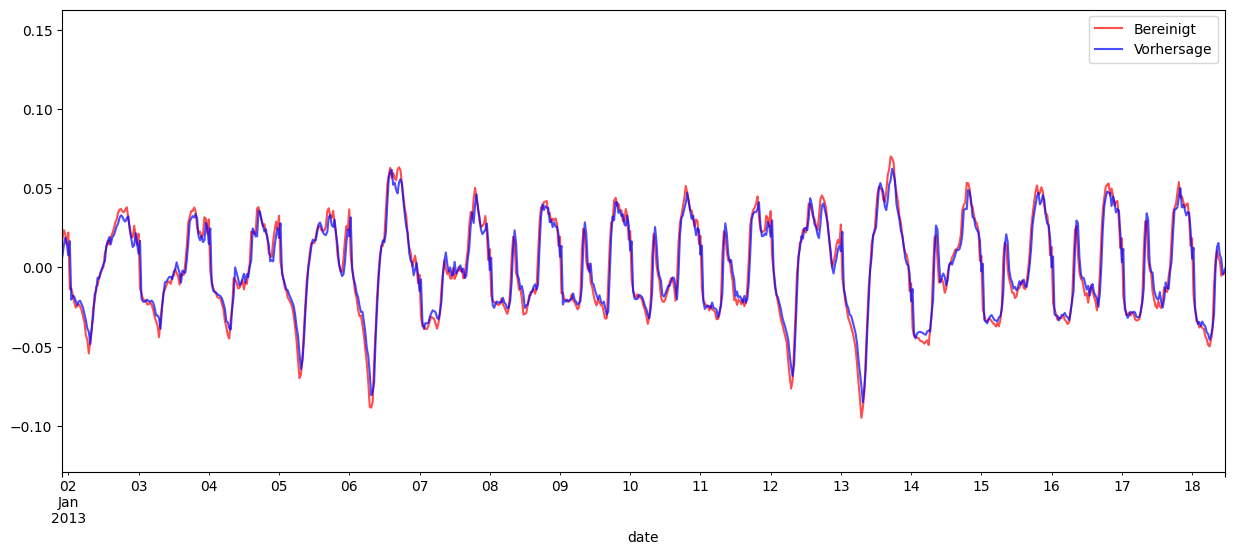

In [16]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.margins(x=0)
df_prediction["kwh_bereinigt"].plot(alpha=0.7, color="red", label="Bereinigt")
df_prediction["kwh_vorhersage"].plot(alpha=0.7, color="blue", label="Vorhersage")

ax.set_xlim(pd.Series(df.index).quantile(0.49), pd.Series(df.index).quantile(0.51))
ax.legend()

/home/sven/Documents/semester-3/.venv/lib/python3.13/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


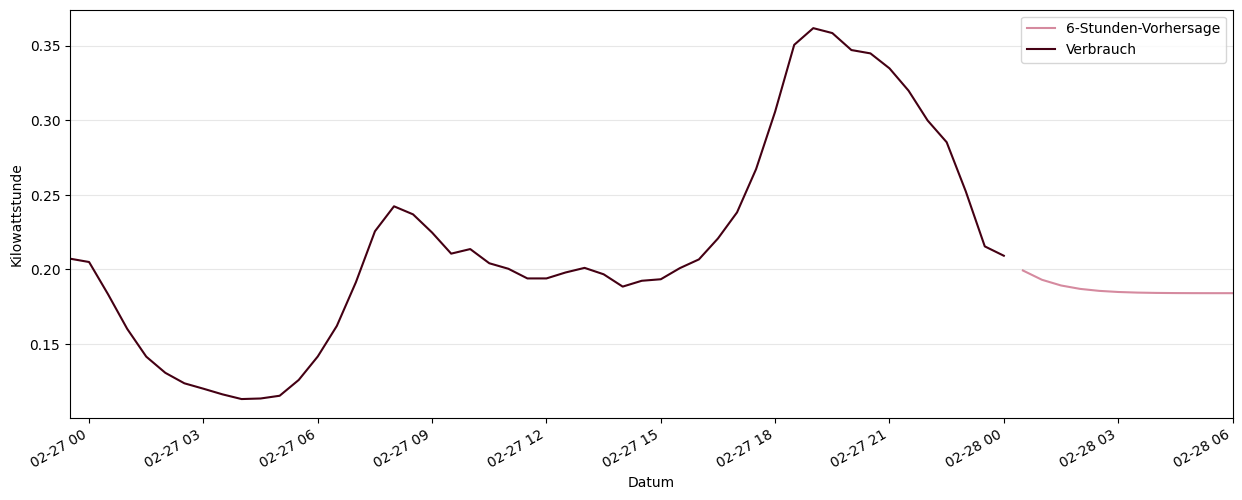

In [18]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(df["kwh"], order=(2, 1, 2)).fit()
forecast = model.forecast(steps=12)

fig, ax = plt.subplots(figsize=(15, 6))
ax.margins(x=0)

ax.plot(forecast.index, forecast, color="#A5002F75", label="6-Stunden-Vorhersage")
df["kwh"].tail(50).plot(ax=ax, color="#440013", label="Verbrauch")
ax.set(
    title="",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.show()

### Varianzen

In [19]:
def variances(df: pd.DataFrame, decomposition: pd.DataFrame = None):
    df_var = df.copy()
    if decomposition:
        df_var["trend"] = decomposition.trend
        df_var["seasonal"] = decomposition.seasonal
        df_var["resid"] = decomposition.resid
    else:
        df_var["trend"] = df_var["kwh_trend"]
        df_var["seasonal"] = df_var["kwh_trendbereinigt_sasion"]
        df_var["resid"] = df_var["kwh_bereinigt"]

    variances = df_var[["kwh", "trend", "seasonal", "resid"]].var()
    variances["ryth"] = decomposition.seasonal.var()
    portions = variances / variances["kwh"]

    print(
        f"Von der Varianz der Zeitreihe werden:\n\t{(portions['trend'] * 100):2.1f}% durch den Trend erklärt"
        f"\n\t{(portions['ryth'] * 100):2.1f}% durch die Periodizität erklärt"
        f"\n\t{(portions['resid'] * 100):2.1f}% haben andere Ursachen (Residuum)"
    )


variances(df, decomposition)

Von der Varianz der Zeitreihe werden:
	25.2% durch den Trend erklärt
	71.7% durch die Periodizität erklärt
	1.7% haben andere Ursachen (Residuum)


Standard Tarif:


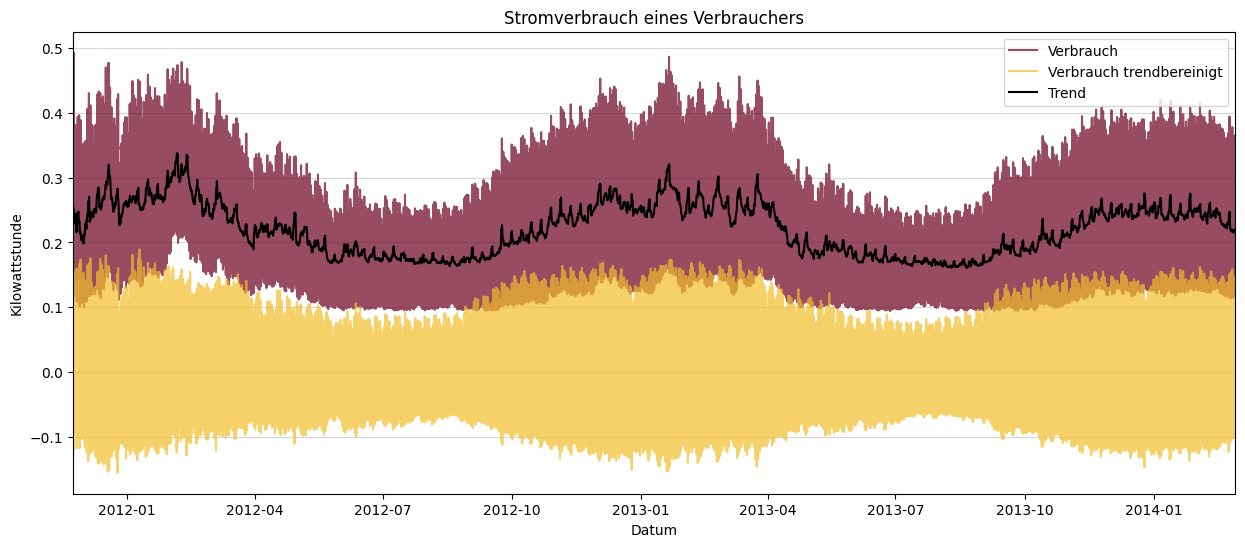

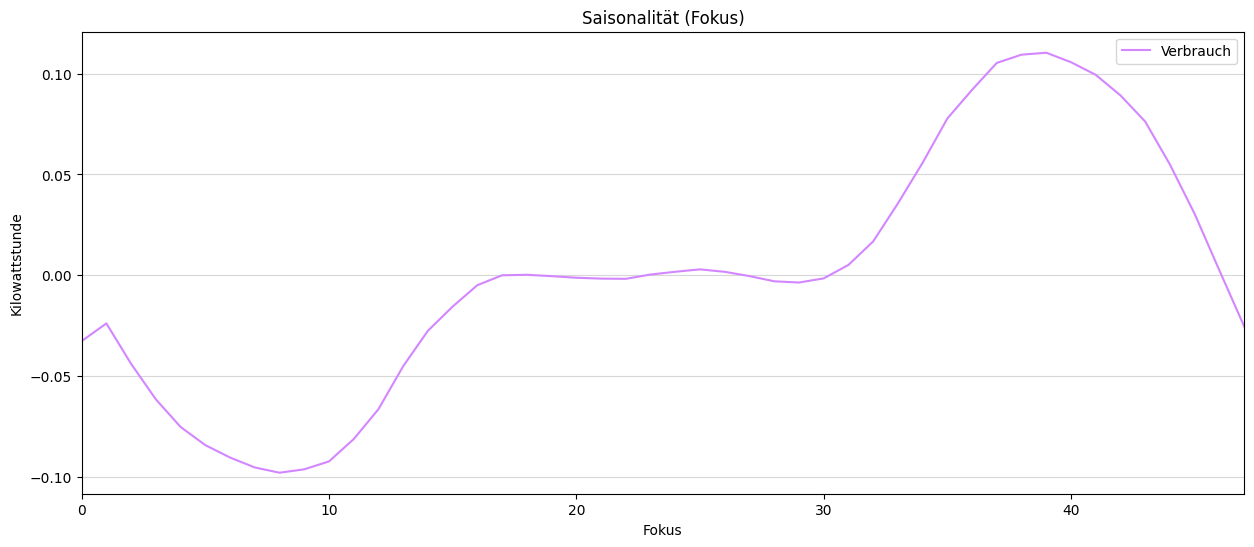

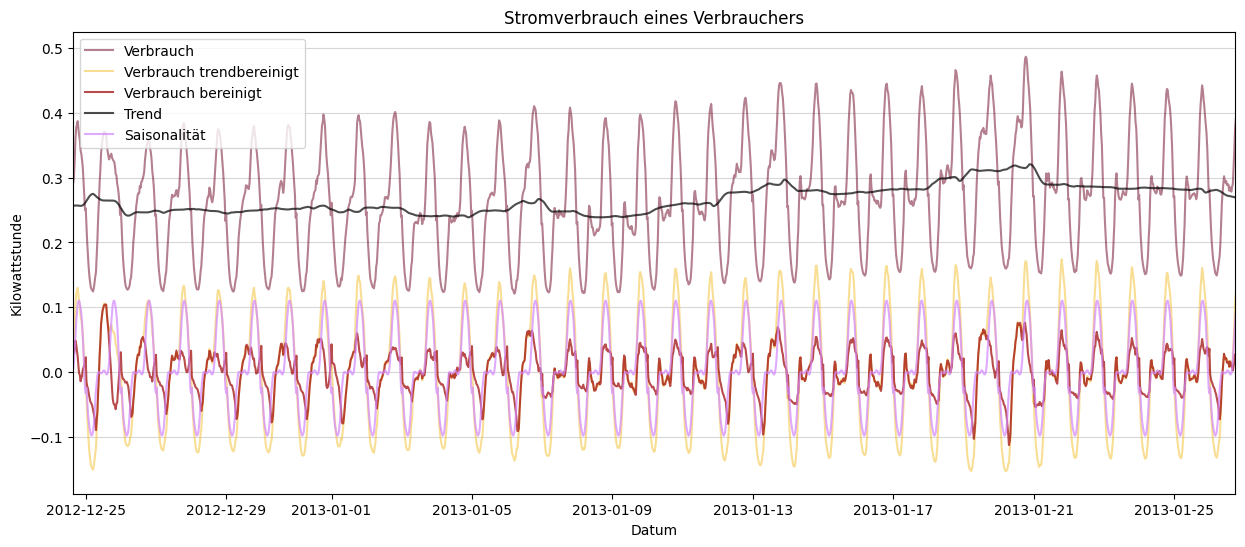

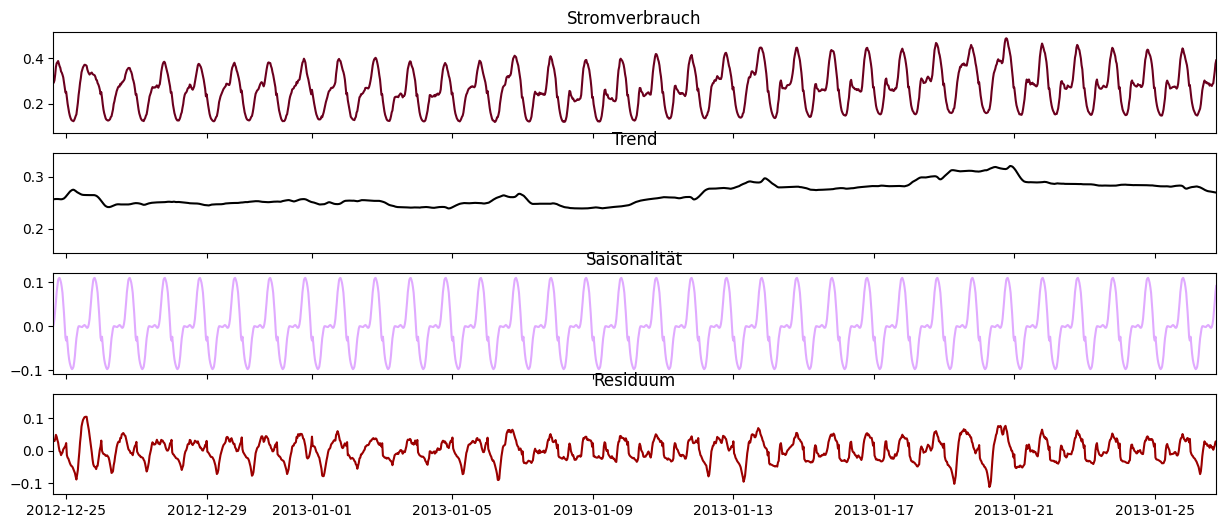

Von der Varianz der Zeitreihe werden:
	25.9% durch den Trend erklärt
	70.9% durch die Periodizität erklärt
	1.8% haben andere Ursachen (Residuum)


Variabler Tarif:


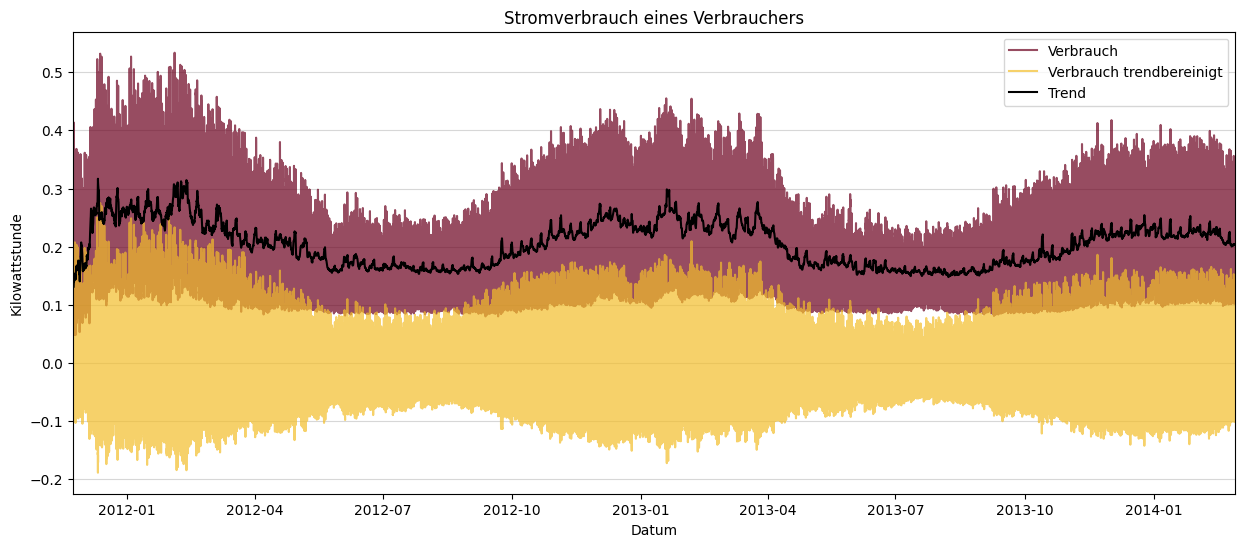

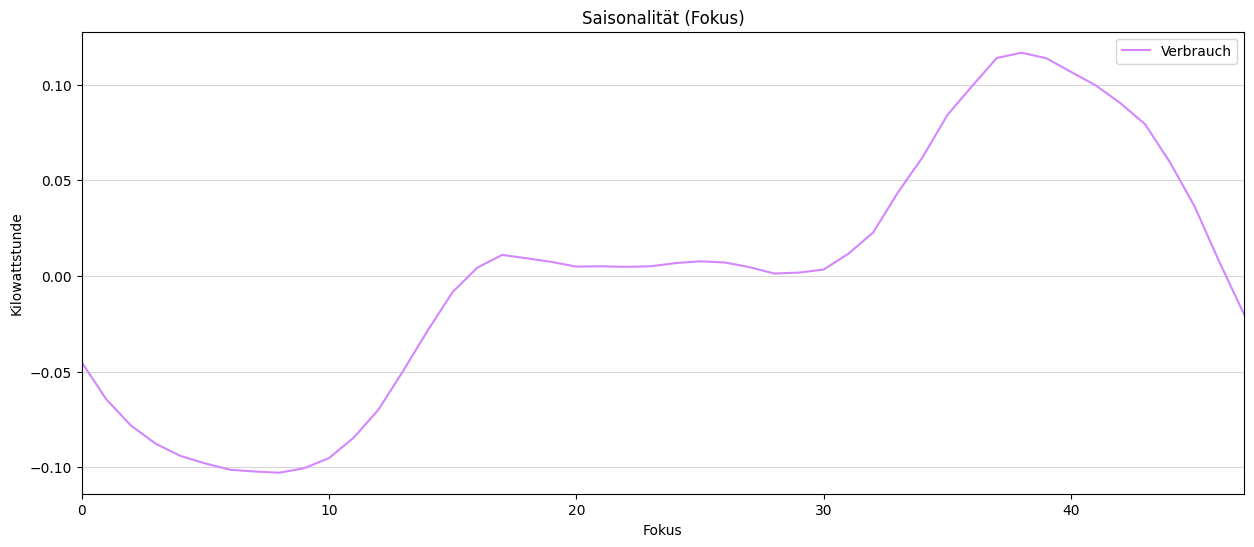

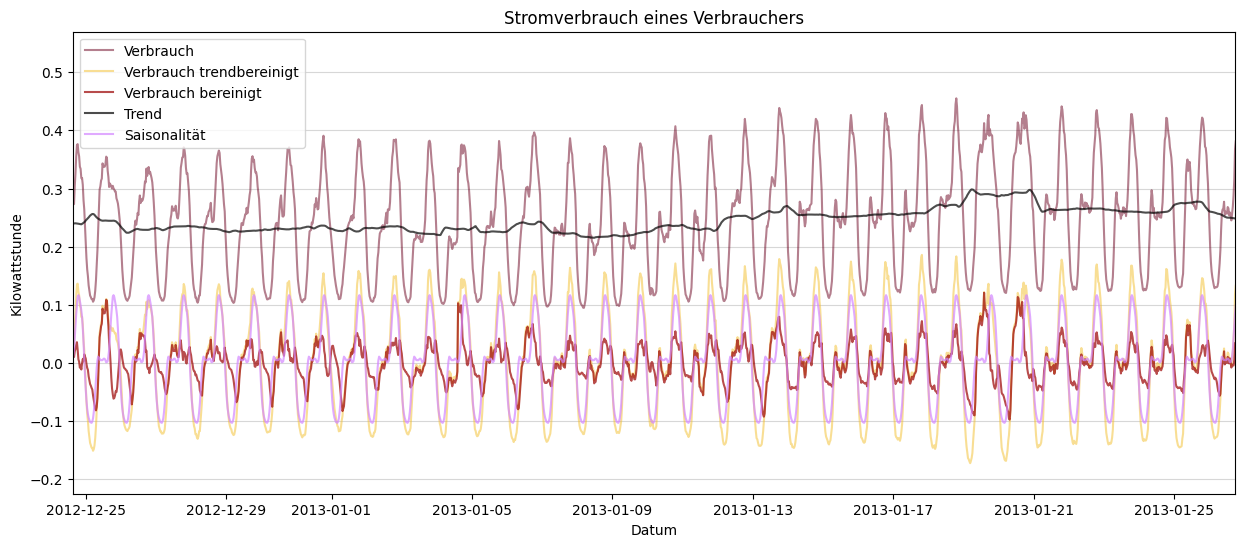

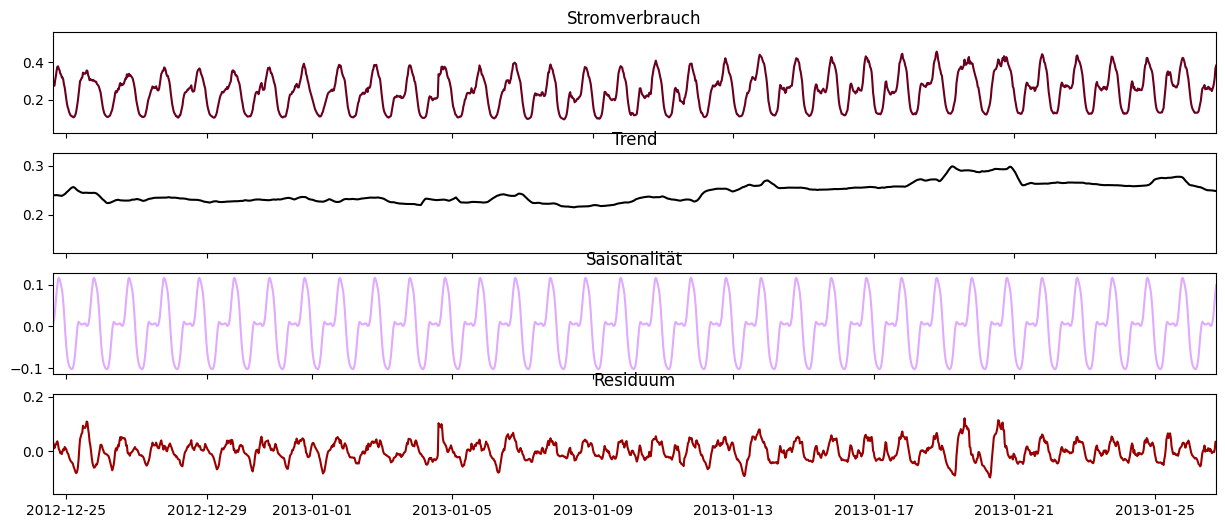

Von der Varianz der Zeitreihe werden:
	21.2% durch den Trend erklärt
	74.9% durch die Periodizität erklärt
	2.5% haben andere Ursachen (Residuum)


In [20]:
df = pd.read_csv("data.csv")


def prep_data(df: pd.DataFrame, rate: str) -> pd.DataFrame:
    df["date"] = pd.to_datetime(df["DateTime"])
    df = df.loc[df["rate"] == rate]
    df["kwh"] = df["KWH"] / df["meters"]
    return df[["date", "KWH", "kwh", "meters"]].set_index("date")[["kwh"]].sort_index().asfreq("30min")


def analyse(df: pd.DataFrame) -> pd.DataFrame:
    return analyse_cleaned(analyse_seasonality(analyse_trend(df)))


df_std = prep_data(df, "Std")
df_tou = prep_data(df, "ToU")

print("Standard Tarif:")
df_std = analyse(df_std)
variances(df_std, STL(df_std["kwh"], period=48).fit())
print("\n\nVariabler Tarif:")
df_tou = analyse(df_tou)
variances(df_tou, STL(df_tou["kwh"], period=48).fit())